In [1]:
# Put import statements here
import os
# hide tensorflow info/warning logs
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["KERAS_BACKEND"] = "torch"
import sys
import subprocess
from pathlib import Path
import json
import pandas as pd


# Local files/code

import src.data_preprocessing.text_preprocessing as text_pre
from src.agents.Visual_Agent import VisualModel
from src.util.logger import Logger
import src.config as config
import src.util.general as general_util
from src.data_preprocessing.TextTokenizer import TextTokenizer
from src.data_preprocessing.TextEmbedder import TextEmbedder
from src.data_preprocessing.USDA_processing import embed_USDA_data
import src.evaluation.visual_evaluator as visual_evaluator
import src.data_preprocessing.image_preprocessing as img_pre
#from src.agents.NLP_Agent import AnswerRanker, build_answer_index, add_usda_records
#import src.evaluation.text_evaluator as text_eval
from src.data_preprocessing.build_training_sets import load_vqa_dataset

2026-10-14 10:56:36.055221: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1791989796.125555     964 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1791989796.138758     964 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1791989796.254338     964 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1791989796.254357     964 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1791989796.254357     964 computation_placer.cc:177] computation placer alr

In [2]:
#load in the GBIF data
#GET THE PATH TO ROOT OF PROJECT
ROOT_PATH = Path.cwd()
print(ROOT_PATH)
TRAIN_DATA = pd.read_csv(config.Data.GBIF.TRAIN_FILE)
TEST_DATA = pd.read_csv(config.Data.GBIF.TEST_FILE)
VAL_DATA = pd.read_csv(config.Data.GBIF.VALIDATION_FILE)

/mnt/c/Users/codyr/Code/AI-572/PlantQA


In [3]:
updated = pd.read_csv("GBIF_UPDATED_SEVERITY.csv").set_index("img_id")
for frame in (TRAIN_DATA, VAL_DATA, TEST_DATA):
    frame["disease"] = frame["image_id"].map(updated["disease"]).fillna(frame["disease"])
    frame["severity"] = frame["image_id"].map(updated["severity"]).fillna(frame["severity"])

In [4]:
VQA_TRAIN = pd.read_csv(config.Data.PlantExpertVQA.TRAIN_FILE)
VQA_VAL = pd.read_csv(config.Data.PlantExpertVQA.VALIDATION_FILE)
VQA_TEST = pd.read_csv(config.Data.PlantExpertVQA.TEST_FILE)
VQA_ROOT_PATH = config.Data.PlantExpertVQA.ROOT.relative_to(config.General.PROJECT_ROOT)
for frame in (VQA_TRAIN, VQA_VAL, VQA_TEST):
    frame["image_path"] = frame["image_path"].apply(lambda p: str(VQA_ROOT_PATH / p))
    frame["genus"] = "unknown"
    frame["family"] = "unknown"
    frame["symbol"] = "unknown"

/tmp/ipykernel_964/2008491469.py:1: DtypeWarning: Columns (9) have mixed types. Specify dtype option on import or set low_memory=False.
  VQA_TRAIN = pd.read_csv(config.Data.PlantExpertVQA.TRAIN_FILE)


In [5]:
##Iterate Through Data sets and fix pathing issue

TRAIN_DATA["image_path"] = TRAIN_DATA["image_path"].apply(lambda x: x.lstrip('//'))
#TRAIN_DATA["image_path"] = TRAIN_DATA["image_path"].apply(lambda p: str(ROOT_PATH / p))


TEST_DATA["image_path"] = TEST_DATA["image_path"].apply(lambda x: x.lstrip('//'))
#TEST_DATA["image_path"] = TEST_DATA["image_path"].apply(lambda p: str(ROOT_PATH / p))

VAL_DATA["image_path"] = VAL_DATA["image_path"].apply(lambda x: x.lstrip(r'/'))
#VAL_DATA["image_path"] = VAL_DATA["image_path"].apply(lambda p: str(ROOT_PATH / p))

print(VAL_DATA.columns)


Index(['image_id', 'image_path', 'symbol', 'group', 'family', 'genus', 'crop',
       'disease', 'category', 'severity'],
      dtype='object')


In [6]:
for i, r in TRAIN_DATA.iterrows():
    print(r["image_path"])

data/GBIF_Pre_Processed/ALSE2/ALSE2_24.jpg
data/GBIF_Pre_Processed/AGGR4/AGGR4_4.jpg
data/GBIF_Pre_Processed/ASBR2/ASBR2_51.jpg
data/GBIF_Pre_Processed/ARTO/ARTO_81.jpg
data/GBIF_Pre_Processed/CASC10/CASC10_7.jpg
data/GBIF_Pre_Processed/ASTE8/ASTE8_36.jpg
data/GBIF_Pre_Processed/CAPA24/CAPA24_55.jpg
data/GBIF_Pre_Processed/AETR/AETR_134.jpg
data/GBIF_Pre_Processed/ASST/ASST_17.jpg
data/GBIF_Pre_Processed/ASTU/ASTU_45.jpg
data/GBIF_Pre_Processed/CABE2/CABE2_40.jpg
data/GBIF_Pre_Processed/ATFI/ATFI_17.jpg
data/GBIF_Pre_Processed/CABA9/CABA9_15.jpg
data/GBIF_Pre_Processed/TSHE/TSHE_40.jpg
data/GBIF_Pre_Processed/TRPR/TRPR_31.jpg
data/GBIF_Pre_Processed/TRFR2/TRFR2_29.jpg
data/GBIF_Pre_Processed/BRSQ2/BRSQ2_56.jpg
data/GBIF_Pre_Processed/UVGR/UVGR_69.jpg
data/GBIF_Pre_Processed/TRGR4/TRGR4_63.jpg
data/GBIF_Pre_Processed/BEJU/BEJU_84.jpg
data/GBIF_Pre_Processed/CACA19/CACA19_49.jpg
data/GBIF_Pre_Processed/CAFO6/CAFO6_66.jpg
data/GBIF_Pre_Processed/BIPI/BIPI_17.jpg
data/GBIF_Pre_Processed/CA

IOPub data rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_data_rate_limit`.

Current values:
ServerApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
ServerApp.rate_limit_window=3.0 (secs)



In [6]:
traits = ["crop", "disease", "severity", "genus", "family", "symbol"]


train_img = pd.concat([
    VisualModel.one_row_per_image(TRAIN_DATA, traits),
    VisualModel.one_row_per_image(VQA_TRAIN, traits)
], ignore_index=True)
val_img = pd.concat([
    VisualModel.one_row_per_image(VAL_DATA, traits),
    VisualModel.one_row_per_image(VQA_VAL, traits)
], ignore_index=True)
test_img = pd.concat([
    VisualModel.one_row_per_image(TEST_DATA, traits),
    VisualModel.one_row_per_image(VQA_TEST, traits)
])
classes = VisualModel.build_classes(train_img, traits)

IMG_SIZE = (224, 224)
train_ds = VisualModel.make_dataset(train_img, classes, config.General.PROJECT_ROOT, training=True, use_mask=True, size = IMG_SIZE)
val_ds  = VisualModel.make_dataset(val_img, classes, config.General.PROJECT_ROOT, use_mask=True, size = IMG_SIZE)



I0000 00:00:1791989823.619029     964 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13495 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4080 SUPER, pci bus id: 0000:01:00.0, compute capability: 8.9


In [8]:
import os
os.environ["KERAS_BACKEND"] = "torch"
import keras
import torch
print(keras.backend.backend())
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

torch
True
NVIDIA GeForce RTX 4080 SUPER


In [9]:
keras.mixed_precision.set_global_policy("mixed_bfloat16")

24274472/24274472 ﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿ 0s 0us/step
Epoch 1/30
6590/6590 ﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿ 1585s 240ms/step - crop_accuracy: 0.4636 - crop_loss: 3.1189 - disease_accuracy: 0.7778 - disease_loss: 0.6619 - family_accuracy: 0.6688 - family_loss: 1.2973 - genus_accuracy: 0.6382 - genus_loss: 1.7878 - loss: 10.4476 - severity_accuracy: 0.6783 - severity_loss: 0.7733 - symbol_accuracy: 0.5517 - symbol_loss: 2.8083 - val_crop_accuracy: 0.4927 - val_crop_loss: 2.6841 - val_disease_accuracy: 0.8463 - val_disease_loss: 0.4379 - val_family_accuracy: 0.6755 - val_family_loss: 1.2152 - val_genus_accuracy: 0.6469 - val_genus_loss: 1.6195 - val_loss: 9.0463 - val_severity_accuracy: 0.

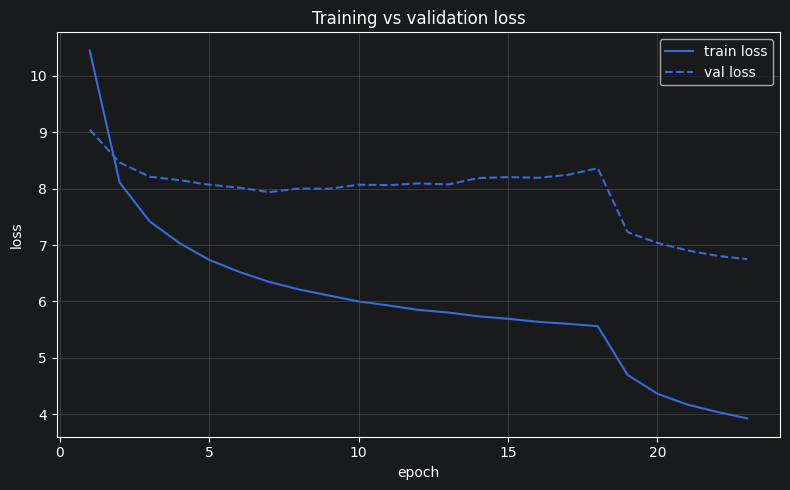

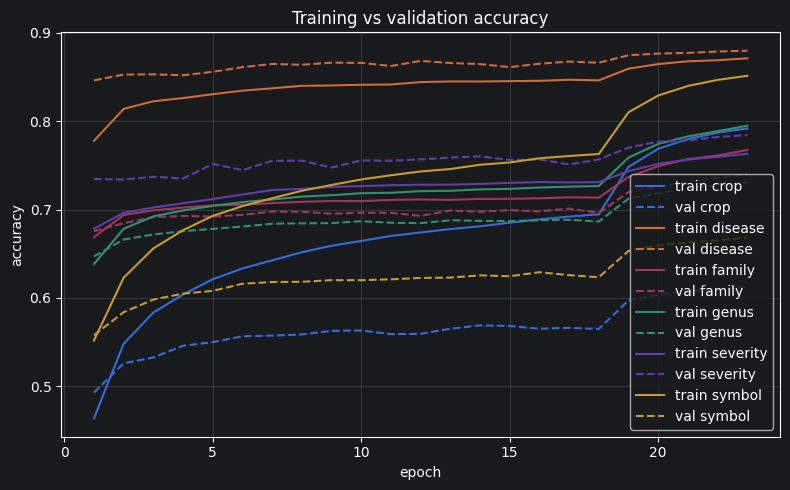

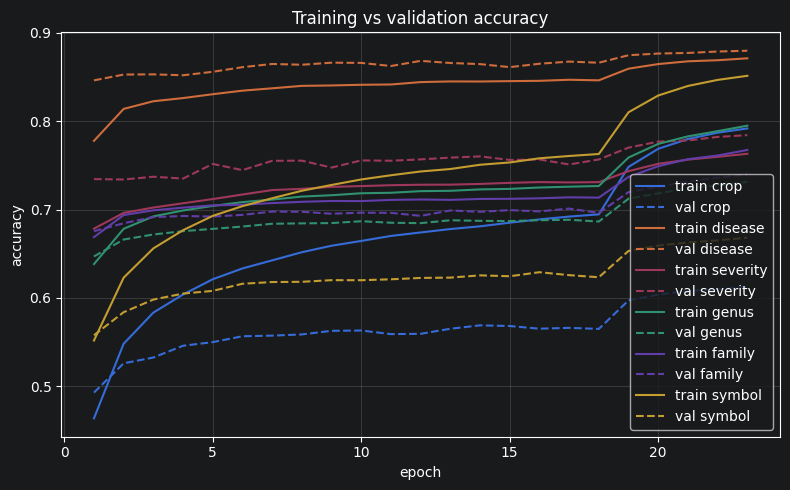

In [9]:

visual_model = VisualModel(classes=classes, img_size=IMG_SIZE, use_mask=True)
visual_model.build()
visual_model.compile()

history_frozen = visual_model.fit(train_ds, val_ds, epochs=30)
visual_model.unfreeze_layers(n_layers=100)
history_tuned = visual_model.fit(train_ds, val_ds, epochs=5)

visual_evaluator.plot_loss(history_frozen, history_tuned)
visual_evaluator.plot_accuracy(history_frozen, history_tuned, heads=["crop", "disease", "severity", "genus", "family", "symbol"])

import json
Path("./models/visual_models/10_11_classes.json").write_text(json.dumps(classes))
visual_model.save(path="./models/visual_models/10_11.keras")
 

In [10]:
# GRID SWEEP ON HYPERPARAMETERS
dropout_options = [.3, .5]
lr_options = [1e-3, 1e-4]
batch_size_options = [32]
size_options = [112, 224]
mask_options = [True, False]

FROZEN_EPOCHS = 30
UNFROZEN_EPOCHS = 5
NUM_LAYERS = 100
TUNE_LR = 1e-5

training_loss_weights = {class_head : 1.0 for class_head in classes}
training_loss_weights["disease"] = 3.0
training_loss_weights["severity"] = 3.0

Path("./models/visual_models/sweep").mkdir(parents=True, exist_ok=True)
Path("./models/visual_models/sweep/classes.json").write_text(json.dumps(classes))

results = []
num_trials = 1
sweep_train = train_img.sample(40000, random_state=0)
sweep_val = val_img.sample(8000, random_state=0)

for batch_size in batch_size_options:
    for lr_option in lr_options:
        for dropout_option in dropout_options:
            for size_option in size_options:
                for mask_option in mask_options:
                    image_size = (size_option, size_option)
                    print(f"\n----------\nTrial {num_trials}\nconfiguration:\nbatch size: {batch_size}\nlearning rate\n{lr_option}\ndropout{dropout_option}\nimage size: {image_size}\nUsing mask: {mask_option}\n----------")

                    train_ds = VisualModel.make_dataset(
                        sweep_train, classes, config.General.PROJECT_ROOT, size=image_size,
                        batch_size=batch_size, training=True, use_mask=mask_option
                    )

                    val_ds = VisualModel.make_dataset(
                        sweep_val, classes, config.General.PROJECT_ROOT, size=image_size,
                        batch_size=batch_size, use_mask=mask_option
                    )

                    sweep_visual_model = VisualModel(
                        classes=classes,
                        img_size=image_size,
                        dropout=dropout_option,
                        loss_weights=training_loss_weights,
                        use_mask=mask_option)


                    sweep_visual_model.build()
                    sweep_visual_model.compile(lr=lr_option)

                    checkpoint = f"./models/visual_models/sweep/trial_{num_trials}.keras"

                    history_frozen = sweep_visual_model.fit(
                        train_ds, val_ds, epochs=FROZEN_EPOCHS,
                        checkpoint_model=checkpoint
                    )

                    sweep_visual_model.unfreeze_layers(n_layers=NUM_LAYERS, lr=TUNE_LR)

                    history_unfrozen = sweep_visual_model.fit(
                        train_ds,
                        val_ds,
                        epochs=UNFROZEN_EPOCHS,
                        checkpoint_model=checkpoint
                    )

                    frozen_best = max(history_frozen.history["val_crop_accuracy"])
                    unfrozen_best = max(history_unfrozen.history["val_crop_accuracy"])

                    results.append({
                        "trial": num_trials,
                        "batch_size": batch_size,
                        "lr": lr_option,
                        "dropout": dropout_option,
                        "image_size": size_option,
                        "use_mask": mask_option,
                        "frozen_best": frozen_best,
                        "unfrozen_best": unfrozen_best,
                        "epochs_frozen_ran": len(history_frozen.history["val_crop_accuracy"]),
                        "checkpoint": checkpoint,
                    })
                    print(
                        f"\ntrial {num_trials}:\n"
                        f"(frozen best: {frozen_best:.4f}, unfrozen best: {unfrozen_best:.4f})"
                    )

                    pd.DataFrame(results).to_csv(
                        "./models/visual_models/sweep/results.csv", index=False)

                    del sweep_visual_model, train_ds, val_ds
                    keras.backend.clear_session()
                    torch.cuda.empty_cache()
                    num_trials += 1

sweep_results = pd.DataFrame(results).sort_values("unfrozen_best", ascending=False)
print("\n" + sweep_results.to_string(index=False))


----------
Trial 1
configuration:
batch size: 32
learning rate
0.001
dropout0.3
image size: (112, 112)
Using mask: True
----------
Epoch 1/30
1250/1250 ﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿ 291s 233ms/step - crop_accuracy: 0.3582 - crop_loss: 4.3029 - disease_accuracy: 0.6962 - disease_loss: 1.0354 - family_accuracy: 0.5991 - family_loss: 1.6859 - genus_accuracy: 0.5702 - genus_loss: 2.4328 - loss: 17.9050 - severity_accuracy: 0.6409 - severity_loss: 0.8683 - symbol_accuracy: 0.5016 - symbol_loss: 3.7725 - val_crop_accuracy: 0.3820 - val_crop_loss: 3.9761 - val_disease_accuracy: 0.7843 - val_disease_loss: 0.6596 - val_family_accuracy: 0.6070 - val_family_loss: 1.6046 - val_genus_accuracy: 0.5634 - val_genus_loss: 2.3238 - val_loss: 15.6713 - val_severity_accuracy: 0.7074 - val_severity_loss: 0.7133 - val_symbol_accuracy: 0.4676 - val_symbol_los

In [11]:
#EVALUATION OF BEST MODEL
model_path = "./models/visual_models/10_11.keras" #best_model["checkpoint"]
classes_path = "./models/visual_models/10_11_classes.json"
#best_model = sweep_results.iloc[0]
visual_model_best = VisualModel.load(model_path= model_path, classes_path=classes_path) #img_size=(int(best_model["image_size"]),)*2)
#Path("./models/visual_models/visual_model_best_classes.json").write_text(json.dumps(classes))
#visual_model_best.save(path="./models/visual_models/visual_model_best.keras")
visual_model_best.model.summary()
test_predictions = visual_evaluator.predict(visual_model_best, test_img, config.General.PROJECT_ROOT)
print(visual_evaluator.metrics_table(test_predictions, num_result=3).to_string())
visual_evaluator.print_report(test_predictions, visual_model_best.classes, "severity")
visual_evaluator.plot_confusion_matrix(test_predictions, visual_model_best.classes, "severity")

Model: "plantqa_visual"

﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿
﷿﷿﷿ Layer (type)        ﷿﷿﷿ Output Shape      ﷿﷿﷿    Param # ﷿﷿﷿ Connected to      ﷿﷿﷿
﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿
﷿﷿﷿ mask (InputLayer)   ﷿﷿﷿ (None, 224, 224,  ﷿﷿﷿          0 ﷿﷿﷿ -                 ﷿﷿﷿
﷿﷿﷿                     ﷿﷿﷿ 2)                ﷿﷿﷿            ﷿﷿﷿                   ﷿﷿﷿
﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿
﷿﷿﷿ conv2d (Conv2D)     ﷿﷿﷿ (None, 224, 224,  ﷿﷿﷿        608 ﷿﷿﷿ mask[0][0]        ﷿﷿﷿
﷿﷿﷿                     ﷿﷿﷿ 32)               ﷿﷿﷿            ﷿﷿﷿                   ﷿﷿﷿
﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿
﷿﷿﷿ batch_normalization ﷿﷿﷿ (None, 224, 224,  ﷿﷿﷿        128 ﷿﷿﷿ conv2d[0][0]      ﷿﷿﷿
﷿﷿﷿ (BatchNormalizatio﷿﷿﷿ ﷿﷿﷿ 32)               ﷿﷿﷿            ﷿﷿﷿                   ﷿﷿﷿
﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿
﷿﷿﷿ max_pooling2d       ﷿﷿﷿ (None, 112, 112,  ﷿﷿﷿          0 ﷿﷿﷿ batch_normalizat﷿﷿﷿ ﷿﷿﷿
﷿﷿﷿ (MaxPooling2D)      ﷿﷿﷿ 32)               ﷿﷿﷿            ﷿﷿﷿                   ﷿﷿﷿
﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿
﷿﷿﷿ conv2d_1 (Conv2D)   ﷿﷿﷿ (None, 112, 112,  ﷿﷿﷿     18,496 ﷿﷿﷿ max_pooling2d[0]﷿﷿﷿ ﷿﷿﷿
﷿﷿﷿                     ﷿﷿﷿ 64)               ﷿﷿﷿            ﷿﷿﷿                   ﷿﷿﷿
﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿
﷿﷿﷿ image (InputLayer)  ﷿﷿﷿ (None, 224, 224,  ﷿﷿﷿          0 ﷿﷿﷿ -                 ﷿﷿﷿
﷿﷿﷿                     ﷿﷿﷿ 3)                ﷿﷿﷿            ﷿﷿﷿                   ﷿﷿﷿
﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿
﷿﷿﷿ batch_normalizatio﷿﷿﷿ ﷿﷿﷿ (None, 112, 112,  ﷿﷿﷿        256 ﷿﷿﷿ conv2d_1[0][0]    ﷿﷿﷿
﷿﷿﷿ (BatchNormalizatio﷿﷿﷿ ﷿﷿﷿ 64)               ﷿﷿﷿            ﷿﷿﷿                   ﷿﷿﷿
﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿
﷿﷿﷿ efficientnetv2-b0   ﷿﷿﷿ (None, 1280)      ﷿﷿﷿  5,919,312 ﷿﷿﷿ image[0][0]       ﷿﷿﷿
﷿﷿﷿ (Functional)        ﷿﷿﷿                   ﷿﷿﷿            ﷿﷿﷿                   ﷿﷿﷿
﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿
﷿﷿﷿ global_average_poo﷿﷿﷿ ﷿﷿﷿ (None, 64)        ﷿﷿﷿          0 ﷿﷿﷿ batch_normalizat﷿﷿﷿ ﷿﷿﷿
﷿﷿﷿ (GlobalAveragePool﷿﷿﷿ ﷿﷿﷿                   ﷿﷿﷿            ﷿﷿﷿                   ﷿﷿﷿
﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿

 Total params: 30,731,474 (117.23 MB)

 Trainable params: 9,574,176 (36.52 MB)

 Non-trainable params: 2,008,944 (7.66 MB)

 Optimizer params: 19,148,354 (73.05 MB)

KeyboardInterrupt: 

In [13]:

FROZEN_EPOCHS = 30
UNFROZEN_EPOCHS = 5
NUM_LAYERS = 100
TUNE_LR = 1e-5

best = (pd.read_csv("./models/visual_models/sweep/results.csv").sort_values("unfrozen_best", ascending=False).iloc[0])
print(f"best hyperparameters: {best}")

BEST_SIZE = (int(best["image_size"]),) * 2
BEST_BATCH = int(best["batch_size"])
BEST_MASK = str(best["use_mask"]).strip().lower() == "true"

train_ds_full = VisualModel.make_dataset(
    train_img,
    classes,
    config.General.PROJECT_ROOT,
    size=BEST_SIZE,
    batch_size=BEST_BATCH,
    training=True,
    use_mask=BEST_MASK
)

val_ds_full = VisualModel.make_dataset(
    val_img,
    classes,
    config.General.PROJECT_ROOT,
    size=BEST_SIZE,
    batch_size=BEST_BATCH,
    use_mask=BEST_MASK
)

final_model = VisualModel(
    classes=classes,
    img_size=BEST_SIZE,
    dropout=float(best["dropout"]),
    use_mask=BEST_MASK
)

final_model.build()
final_model.compile(lr=float(best["lr"]))

best_checkpoint = "./models/visual_models/final_best.keras"
history_frozen = final_model.fit(train_ds_full, val_ds_full, epochs=30, checkpoint_model=best_checkpoint)
final_model.unfreeze_layers(n_layers=NUM_LAYERS, lr=TUNE_LR)
history_tuned = final_model.fit(train_ds_full, val_ds_full, epochs=5, checkpoint_model=best)

final_model.save("./models/visual_models/final.keras")
Path("./models/visual_models/final_classes.json").write_text(json.dumps(classes))

final_model.model.summary()
test_predictions = visual_evaluator.predict(final_model, test_img, config.General.PROJECT_ROOT)
print(visual_evaluator.metrics_table(test_predictions, num_result=3).to_string())
visual_evaluator.plot_loss(history_frozen, history_tuned)
visual_evaluator.plot_accuracy(history_frozen, history_tuned, heads=["crop", "disease", "severity", "genus", "family", "symbol"])
visual_evaluator.print_report(test_predictions, final_model.classes, "severity")
visual_evaluator.plot_confusion_matrix(test_predictions, final_model.classes, "severity")

best hyperparameters: trial                                                         8
batch_size                                                   32
lr                                                        0.001
dropout                                                     0.5
image_size                                                  224
use_mask                                                  False
frozen_best                                             0.48925
unfrozen_best                                             0.505
epochs_frozen_ran                                            30
checkpoint           ./models/visual_models/sweep/trial_8.keras
Name: 7, dtype: object
Epoch 1/30
6590/6590 ﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿ 1194s 181ms/step - crop_accuracy: 0.4346 - crop_loss: 3.4512 - disease_accuracy: 0.6882 - disease_loss: 0.8946 - family_accuracy: 0.6511 - family_loss: 1.3908 - genus_accuracy: 0.6204 - genus_loss: 1.9316 - loss: 11.7330 - severity_a

AttributeError: 'Series' object has no attribute 'endswith'

In [14]:
tuned_checkpoint = "./models/visual_models/final_best_tuned.keras"
history_tuned = final_model.fit(train_ds_full, val_ds_full, epochs=5, checkpoint_model=tuned_checkpoint)

final_model.save("./models/visual_models/final.keras")
Path("./models/visual_models/final_classes.json").write_text(json.dumps(classes))

Epoch 1/5
6590/6590 ﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿ 1330s 202ms/step - crop_accuracy: 0.6328 - crop_loss: 1.6487 - disease_accuracy: 0.7507 - disease_loss: 0.6371 - family_accuracy: 0.7021 - family_loss: 1.0881 - genus_accuracy: 0.7038 - genus_loss: 1.2684 - loss: 6.9265 - severity_accuracy: 0.6350 - severity_loss: 0.8794 - symbol_accuracy: 0.7051 - symbol_loss: 1.4049 - val_crop_accuracy: 0.5889 - val_crop_loss: 2.0544 - val_disease_accuracy: 0.7907 - val_disease_loss: 0.5137 - val_family_accuracy: 0.7053 - val_family_loss: 1.0785 - val_genus_accuracy: 0.6972 - val_genus_loss: 1.3228 - val_loss: 7.6146 - val_severity_accuracy: 0.6774 - val_severity_loss: 0.7821 - val_symbol_accuracy: 0.6445 - val_symbol_loss: 1.8631
Epoch 2/5
6590/6590 ﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿ 1327s 201ms/step - crop_accuracy: 0.6545 - crop_loss: 1.5166 - disease_accuracy: 0.7620 - disease_loss: 0.6026 - family_accuracy: 0.7164 - family_loss: 1.0243 - ge

80377

Model: "plantqa_visual"

﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿
﷿﷿﷿ Layer (type)        ﷿﷿﷿ Output Shape      ﷿﷿﷿    Param # ﷿﷿﷿ Connected to      ﷿﷿﷿
﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿
﷿﷿﷿ image (InputLayer)  ﷿﷿﷿ (None, 224, 224,  ﷿﷿﷿          0 ﷿﷿﷿ -                 ﷿﷿﷿
﷿﷿﷿                     ﷿﷿﷿ 3)                ﷿﷿﷿            ﷿﷿﷿                   ﷿﷿﷿
﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿
﷿﷿﷿ efficientnetv2-b0   ﷿﷿﷿ (None, 1280)      ﷿﷿﷿  5,919,312 ﷿﷿﷿ image[0][0]       ﷿﷿﷿
﷿﷿﷿ (Functional)        ﷿﷿﷿                   ﷿﷿﷿            ﷿﷿﷿                   ﷿﷿﷿
﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿
﷿﷿﷿ dropout_2 (Dropout) ﷿﷿﷿ (None, 1280)      ﷿﷿﷿          0 ﷿﷿﷿ efficientnetv2-b﷿﷿﷿ ﷿﷿﷿
﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿
﷿﷿﷿ crop (Dense)        ﷿﷿﷿ (None, 1683)      ﷿﷿﷿  2,155,923 ﷿﷿﷿ dropout_2[0][0]   ﷿﷿﷿
﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿
﷿﷿﷿ disease (Dense)     ﷿﷿﷿ (None, 95)        ﷿﷿﷿    121,695 ﷿﷿﷿ dropout_2[0][0]   ﷿﷿﷿
﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿
﷿﷿﷿ severity (Dense)    ﷿﷿﷿ (None, 5)         ﷿﷿﷿      6,405 ﷿﷿﷿ dropout_2[0][0]   ﷿﷿﷿
﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿
﷿﷿﷿ genus (Dense)       ﷿﷿﷿ (None, 441)       ﷿﷿﷿    564,921 ﷿﷿﷿ dropout_2[0][0]   ﷿﷿﷿
﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿
﷿﷿﷿ family (Dense)      ﷿﷿﷿ (None, 130)       ﷿﷿﷿    166,530 ﷿﷿﷿ dropout_2[0][0]   ﷿﷿﷿
﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿
﷿﷿﷿ symbol (Dense)      ﷿﷿﷿ (None, 1646)      ﷿﷿﷿  2,108,526 ﷿﷿﷿ dropout_2[0][0]   ﷿﷿﷿
﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿

 Total params: 29,112,434 (111.06 MB)

 Trainable params: 9,034,560 (34.46 MB)

 Non-trainable params: 2,008,752 (7.66 MB)

 Optimizer params: 18,069,122 (68.93 MB)

          num results  accuracy  top3_accuracy  macro average f1
head                                                            
crop            61138     0.636          0.761             0.383
disease         61138     0.800          0.987             0.708
severity        61138     0.691          0.975             0.591
genus           61138     0.743          0.835             0.420
family          61138     0.749          0.865             0.415
symbol          61138     0.693          0.771             0.371


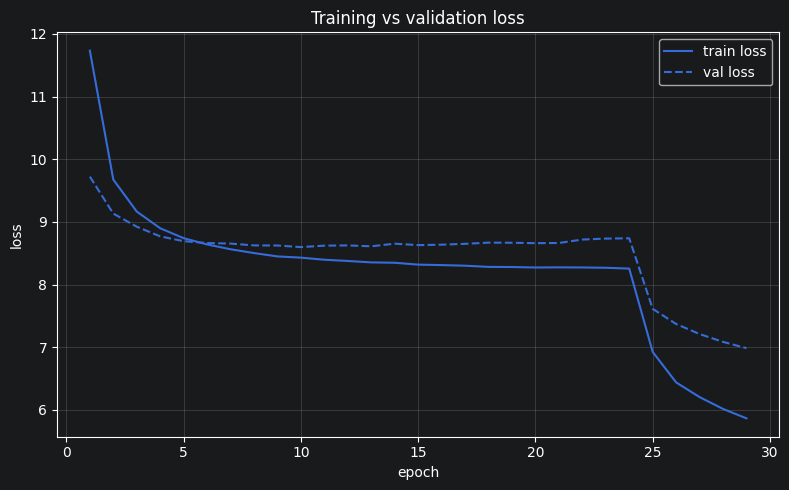

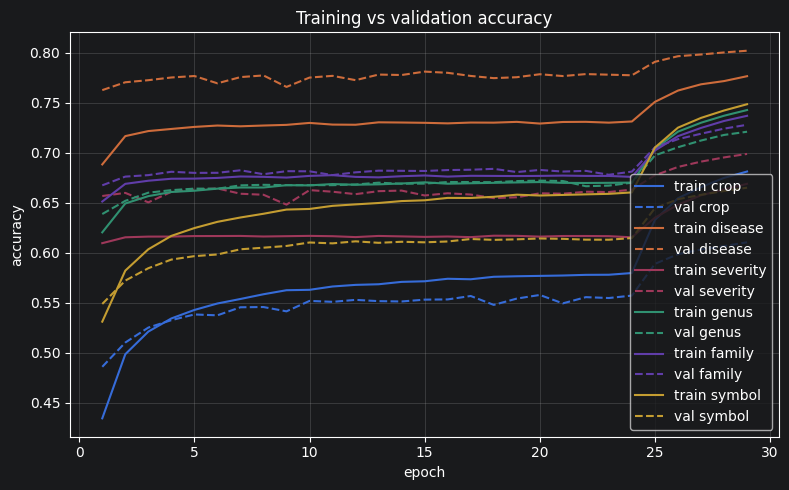

16:06:31 [INFO    ]: 
severity classification report:
              precision    recall  f1-score   support

     HEALTHY       0.78      0.89      0.83     30909
        MILD       0.54      0.34      0.42      7691
    MODERATE       0.61      0.55      0.58      9243
      SEVERE       0.72      0.60      0.65      5448
     UNKNOWN       0.47      0.47      0.47      7847

    accuracy                           0.69     61138
   macro avg       0.62      0.57      0.59     61138
weighted avg       0.68      0.69      0.68     61138



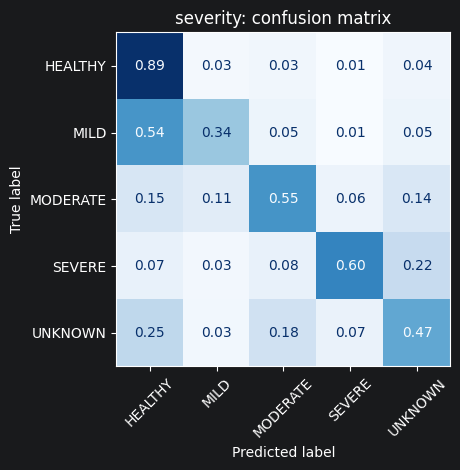

In [15]:
final_model.model.summary()
test_predictions = visual_evaluator.predict(final_model, test_img, config.General.PROJECT_ROOT)
print(visual_evaluator.metrics_table(test_predictions, num_result=3).to_string())
visual_evaluator.plot_loss(history_frozen, history_tuned)
visual_evaluator.plot_accuracy(history_frozen, history_tuned, heads=["crop", "disease", "severity", "genus", "family", "symbol"])
visual_evaluator.print_report(test_predictions, final_model.classes, "severity")
visual_evaluator.plot_confusion_matrix(test_predictions, final_model.classes, "severity")